In [1]:
!pip install kaggle --quiet

Save teh kaggle.json from kaggle website and upload here.

In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"ninaddilipraojoshi","key":"b941439a0c3b28f9d4e7735d9a12e4b0"}'}

Loading the dataset

In [3]:
import os
import shutil

os.makedirs("/root/.kaggle", exist_ok=True)

shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")

os.chmod("/root/.kaggle/kaggle.json", 0o600)

In [4]:
!kaggle datasets download -d mssmartypants/rice-type-classification

Dataset URL: https://www.kaggle.com/datasets/mssmartypants/rice-type-classification
License(s): copyright-authors
100% 888k/888k [00:00<00:00, 114MB/s]



In [5]:
import zipfile
import os

with zipfile.ZipFile("rice-type-classification.zip", "r") as zip_ref:
    zip_ref.extractall("rice_dataset")

print(os.listdir("rice_dataset"))

['riceClassification.csv']


Prerequisits

In [6]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
from torchsummary import summary
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [7]:
df = pd.read_csv("/content/rice_dataset/riceClassification.csv")
df.head()

,id,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,1,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,4,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,5,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


Cleaning the dataset i.e. Dropping repeated values and id column

In [8]:
df.dropna(inplace=True)
df.drop(['id'], axis=1, inplace=True)
df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1


In [9]:
df.shape

(18185, 11)

In [10]:
print(df["Class"].unique())

[1 0]


In [11]:
print(df["Class"].value_counts())

Class
1    9985
0    8200
Name: count, dtype: int64


Normalization

In [12]:
original_df = df.copy()

for column in df.columns:
  df[column] = df[column]/df[column].abs().max()

df.head()

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,0.444368,0.503404,0.775435,0.744658,0.424873,0.666610,0.741661,0.537029,0.844997,0.368316,1.0
1,0.281293,0.407681,0.622653,0.750489,0.273892,0.530370,0.804230,0.409661,0.919215,0.371471,1.0
2,0.298531,0.416421,0.630442,0.756341,0.284520,0.546380,0.856278,0.412994,0.959862,0.374747,1.0
3,0.300979,0.420463,0.629049,0.764024,0.286791,0.548616,0.883772,0.414262,0.961818,0.379222,1.0
4,0.361704,0.464626,0.682901,0.775033,0.345385,0.601418,0.867808,0.452954,0.966836,0.386007,1.0


Seperating input and output

In [13]:
X = np.array(df.iloc[:, :-1])
Y = np.array(df.iloc[:, -1])

Train test validation split

In [14]:
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.3)

In [15]:
x_test, x_val, y_test, y_val = train_test_split(x_test, y_test, test_size=0.5)

In [16]:
print(x_train.shape, x_val.shape, x_test.shape)

(12729, 10) (2728, 10) (2728, 10)


This is used for converting numpy array into tensor.

Pytorch can only process tensor format data.

Here Dataset class is defined in pytorch, we are redefining it using our own dataset.

In [17]:
class dataset(Dataset):
  def __init__(self, X, Y):
    self.X = torch.tensor(X, dtype = torch.float32).to(device)
    self.Y = torch.tensor(Y, dtype = torch.float32).to(device)

  def __len__(self):
    return len(self.X)

  def __getitem__(self, index):
    return self.X[index], self.Y[index]

In [18]:
training_data = dataset(x_train, y_train)
validation_data = dataset(x_val, y_val)
testing_data = dataset(x_test, y_test)

DataLoader loads the tensor from previous step and divide it into batches.

In [19]:
train_dataloader = DataLoader(training_data, batch_size = 32, shuffle = True)
validation_dataloader = DataLoader(validation_data, batch_size = 32, shuffle = True)
testing_dataloader = DataLoader(testing_data, batch_size = 32, shuffle = True)

In [20]:
for x, y in train_dataloader:
  print(x)
  print("======")
  print(y)
  break

tensor([[0.8470, 0.8567, 0.8588, 0.9228, 0.8075, 0.9203, 0.8337, 0.7354, 0.8588,
         0.5660],
        [0.7230, 0.7714, 0.8161, 0.9093, 0.6881, 0.8503, 0.7289, 0.6704, 0.8822,
         0.5363],
        [0.8788, 0.8719, 0.8738, 0.9229, 0.8388, 0.9375, 0.7055, 0.7547, 0.8461,
         0.5661],
        [0.6350, 0.8544, 0.6511, 0.9715, 0.6042, 0.7968, 0.5343, 0.6951, 0.7207,
         0.7445],
        [0.5991, 0.8801, 0.6038, 0.9837, 0.5786, 0.7740, 0.6867, 0.7007, 0.6692,
         0.8269],
        [0.6484, 0.8788, 0.6430, 0.9765, 0.6146, 0.8052, 0.5716, 0.7012, 0.7232,
         0.7754],
        [0.9143, 0.9124, 0.8755, 0.9327, 0.8656, 0.9562, 0.6194, 0.7713, 0.8428,
         0.5913],
        [0.8951, 0.8670, 0.8965, 0.9152, 0.8542, 0.9461, 0.6896, 0.7545, 0.8624,
         0.5487],
        [0.5577, 0.8701, 0.5630, 0.9894, 0.5322, 0.7468, 0.4956, 0.6808, 0.6599,
         0.8769],
        [0.5424, 0.8321, 0.5754, 0.9829, 0.5197, 0.7365, 0.5137, 0.6597, 0.6836,
         0.8205],
        [0

Model Definition

In [21]:
HIDDEN_NEURONS = 10
class MyModel(nn.Module):
  def __init__(self):
    super(MyModel, self).__init__()

    self.input_layer = nn.Linear(X.shape[1], HIDDEN_NEURONS)
    self.linear = nn.Linear(HIDDEN_NEURONS, 1)
    self.sigmoid = nn.Sigmoid()

  def forward(self, x):
    x = self.input_layer(x)
    x = self.linear(x)
    x = self.sigmoid(x)
    return x

model = MyModel().to(device)

In [22]:
summary(model, (X.shape[1],))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Linear-1                   [-1, 10]             110
            Linear-2                    [-1, 1]              11
           Sigmoid-3                    [-1, 1]               0
Total params: 121
Trainable params: 121
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00
----------------------------------------------------------------


Binary Crossentropy

ADAM Optimizer

In [23]:
criterion = nn.BCELoss()
optimizer = Adam(model.parameters(), lr=1e-3)

In [24]:
# Initialize lists to store results
total_loss_train_plot = []
total_loss_validation_plot = []
total_acc_train_plot = []
total_acc_validation_plot = []

# The outer loop: Training for 10 epochs
epochs = 10
for epoch in range(epochs):
  total_acc_train = 0
  total_loss_train = 0
  total_acc_val = 0
  total_loss_val = 0

# Training loop: Processing batches
  for data in train_dataloader:
    inputs, labels = data

# Generate predictions
    prediction = model(inputs).squeeze(1)
    # print(prediction.shape)
    # print(prediction.squeeze(1).shape)

# Calculate the loss
    batch_loss = criterion(prediction, labels)
    total_loss_train += batch_loss.item()

# Calculate training accuracy
#'round()'Round the predictions
#'== labels'Compare predictions with actual labels
#'sum().item()'Count the correct predictions
    acc = ((prediction).round() == labels).sum().item()
    total_acc_train += acc

# Backpropagation and updating model parameters
    batch_loss.backward() #Calculates the gradients of the loss with respect to the model's trainable parameters using backpropagation.
    optimizer.step() #Updates the model's trainable parameters using the calculated gradients and the optimization algorithm you selected.
    optimizer.zero_grad() #Resets the gradients stored in the model's parameters.

#The training sequence is therefore:
# 1. Forward pass: Generate predictions.
# 2. Calculate loss.
# 3. Backward pass: Calculate gradients.
# 4. Optimizer step: Update parameters.
# 5. Reset gradients before the next batch.

#
  with torch.no_grad():
    for data in validation_dataloader:
      inputs, labels = data

      prediction = model(inputs).squeeze(1)
      batch_loss = criterion(prediction, labels)
      total_loss_val += batch_loss.item()

      acc = ((prediction).round() == labels).sum().item()
      total_acc_val += acc

  total_loss_train_plot.append(round(total_loss_train/1000, 4))
  total_loss_validation_plot.append(round(total_loss_val/1000, 4))
  total_acc_train_plot.append(round(total_acc_train/training_data.__len__() * 100, 4))
  total_acc_validation_plot.append(round(total_acc_val/validation_data.__len__() * 100, 4))

  print(f'''Epoch no. {epoch+1} Train Loss: {round(total_loss_train/1000, 4)} Train Accuracy {round(total_acc_train/training_data.__len__() * 100, 4)}
            Validation Loss: {round(total_loss_val/1000, 4)} Validation Accuracy: {round(total_acc_val/validation_data.__len__() * 100, 4)}''')
  print("="*25)

  #     break
  #   # break
  # break

Epoch no. 1 Train Loss: 0.2402 Train Accuracy 81.7189
            Validation Loss: 0.0408 Validation Accuracy: 97.8739
Epoch no. 2 Train Loss: 0.1328 Train Accuracy 97.926
            Validation Loss: 0.019 Validation Accuracy: 98.4238
Epoch no. 3 Train Loss: 0.0647 Train Accuracy 98.2245
            Validation Loss: 0.0104 Validation Accuracy: 98.5704
Epoch no. 4 Train Loss: 0.0399 Train Accuracy 98.4052
            Validation Loss: 0.0072 Validation Accuracy: 98.6437
Epoch no. 5 Train Loss: 0.0296 Train Accuracy 98.5388
            Validation Loss: 0.0056 Validation Accuracy: 98.717
Epoch no. 6 Train Loss: 0.0246 Train Accuracy 98.5623
            Validation Loss: 0.0049 Validation Accuracy: 98.7903
Epoch no. 7 Train Loss: 0.0217 Train Accuracy 98.5859
            Validation Loss: 0.0043 Validation Accuracy: 98.717
Epoch no. 8 Train Loss: 0.02 Train Accuracy 98.6173
            Validation Loss: 0.0041 Validation Accuracy: 98.7903
Epoch no. 9 Train Loss: 0.0189 Train Accuracy 98.6095


In [25]:
with torch.no_grad():
  total_loss_test = 0
  total_acc_test = 0
  for data in testing_dataloader:
    inputs, labels = data
    prediction = model(inputs).squeeze(1)

    batch_loss_test = criterion(prediction, labels).item()
    total_loss_test += batch_loss_test
    acc = ((prediction).round() == labels).sum().item()
    total_acc_test += acc

print("Accuracy: ", round(total_acc_test/testing_data.__len__() * 100, 4))

Accuracy:  98.5337


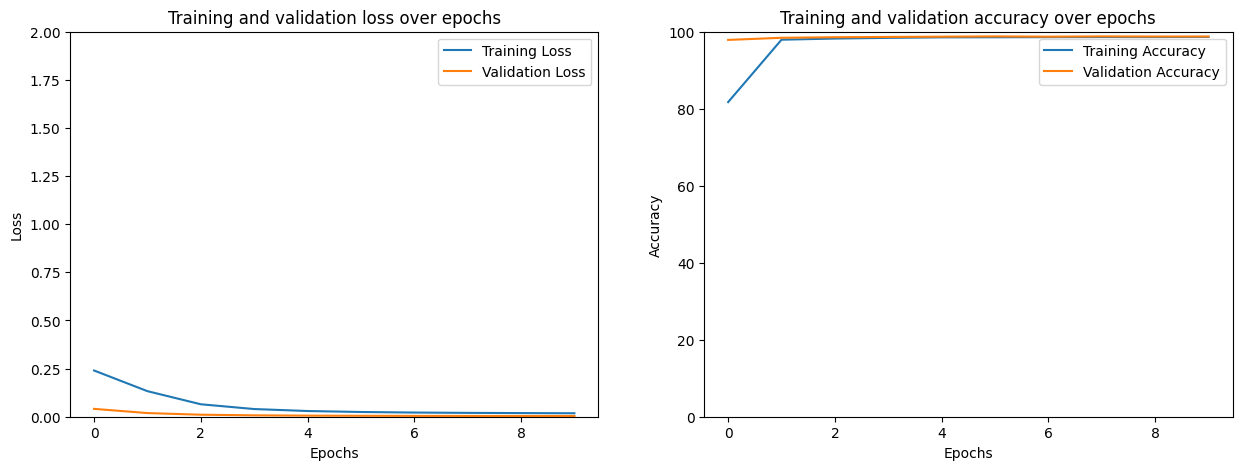

In [26]:
fig, axs = plt.subplots(nrows = 1, ncols=2, figsize=(15,5))
axs[0].plot(total_loss_train_plot, label = 'Training Loss')
axs[0].plot(total_loss_validation_plot, label = 'Validation Loss')
axs[0].set_title("Training and validation loss over epochs")
axs[0].set_xlabel("Epochs")
axs[0].set_ylabel("Loss")
axs[0].set_ylim(0,2)
axs[0].legend()

axs[1].plot(total_acc_train_plot, label = 'Training Accuracy')
axs[1].plot(total_acc_validation_plot, label = 'Validation Accuracy')
axs[1].set_title("Training and validation accuracy over epochs")
axs[1].set_xlabel("Epochs")
axs[1].set_ylabel("Accuracy")
axs[1].set_ylim(0,100)
axs[1].legend()

plt.show()

In [27]:
original_df

,Area,MajorAxisLength,MinorAxisLength,Eccentricity,ConvexArea,EquivDiameter,Extent,Perimeter,Roundness,AspectRation,Class
0,4537,92.229316,64.012769,0.719916,4677,76.004525,0.657536,273.085,0.764510,1.440796,1
1,2872,74.691881,51.400454,0.725553,3015,60.471018,0.713009,208.317,0.831658,1.453137,1
2,3048,76.293164,52.043491,0.731211,3132,62.296341,0.759153,210.012,0.868434,1.465950,1
3,3073,77.033628,51.928487,0.738639,3157,62.551300,0.783529,210.657,0.870203,1.483456,1
4,3693,85.124785,56.374021,0.749282,3802,68.571668,0.769375,230.332,0.874743,1.510000,1
...,...,...,...,...,...,...,...,...,...,...,...
18180,5853,148.624571,51.029281,0.939210,6008,86.326537,0.498594,332.960,0.663444,2.912535,0
18181,7585,169.593996,58.141659,0.939398,7806,98.272692,0.647461,385.506,0.641362,2.916910,0
18182,6365,154.777085,52.908085,0.939760,6531,90.023162,0.561287,342.253,0.682832,2.925396,0
18183,5960,151.397924,51.474600,0.940427,6189,87.112041,0.492399,343.371,0.635227,2.941216,0


In [28]:
area = 2353/original_df['Area'].abs().max()
MajorAxisLength = 81/original_df['MajorAxisLength'].abs().max()
MinorAxisLength = 42/original_df['MinorAxisLength'].abs().max()
Eccentricity = 0.32/original_df['Eccentricity'].abs().max()
ConvexArea = 3253/original_df['ConvexArea'].abs().max()
EquivDiameter = 55/original_df['EquivDiameter'].abs().max()
Extent = 0.68/original_df['Extent'].abs().max()
Perimeter = 297/original_df['Perimeter'].abs().max()
Roundness = 0.677/original_df['Roundness'].abs().max()
AspectRation = 2.4/original_df['AspectRation'].abs().max()
# Class = 6/original_df['Class'].abs().max()


my_prediction = model(torch.tensor([area, MajorAxisLength, MinorAxisLength, Eccentricity, ConvexArea, EquivDiameter, Extent, Perimeter, Roundness, AspectRation], dtype = torch.float32).to(device))

In [29]:
round(my_prediction.item())

1